## Classification on Flower102 Dataset from Torchvision


We are working on torchvision.datasets.Flower102, a dataset with 8,189 images with 102 classes

### Imports + config

In [ ]:
!pip install anthropic gradio openai

In [ ]:
import torch
import gradio
import openai
#import config
import anthropic
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

In [ ]:
# set the batch size and validation data split
BATCH_SIZE = 64
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
# set the number of epochs and learning rate
EPOCHS = 10
LEARNING_RATE = 0.001
# set the device to cuda if available, else use cpu
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# set the seed for reproducibility
SEED = 42
# set the number of workers for data loading
NUM_WORKERS = 2
# set the number of classes for the flowers dataset
NUM_CLASSES = 102


#### Initial approach

In [ ]:
# 1. Define transformations for the dataset
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ------------------- Part 2: Load the dataset and create DataLoaders -------------------
# Divide it into training and validation sets
# 2. Load the dataset
train_dataset = datasets.Flowers102(
    root='.data',
    split='train',
    download=True,
    transform=transform
)

val_dataset = datasets.Flowers102(
    root='.data',
    split='val',
    download=True,
    transform=transform
)

# 3. Create a DataLoader for the dataset

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=True)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=False)

# 4. Download and load the test dataset
test_dataset = datasets.Flowers102(
    root='.data',
    split='test',
    download=True,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=False
)

In [ ]:
# print the number of samples in each dataset
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")

Number of training samples: 1020
Number of validation samples: 1020
Number of test samples: 6149


The repartition of the dataset is not good. We decide to merge all data and split it by ourself such that we have more data to learn from.

#### Second approach

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load ALL splits (no transforms yet, just to collect paths + labels)
all_splits = ['train', 'val', 'test']
all_paths, all_labels = [], []

for split in all_splits:
    ds = datasets.Flowers102(root='.data', split=split, download=True)
    all_paths.extend(ds._image_files)   # list of full paths
    all_labels.extend(ds._labels)        # 1-indexed labels

print(f"Total images: {len(all_paths)}")  # 8189

# 2. Stratified split: 70% train / 15% val / 15% test
#    Split between test (15%) and train_val (85%)
Path_temp, Path_test, y_temp, y_test = train_test_split(
    all_paths, all_labels, test_size=0.15, stratify=all_labels, random_state=SEED
)
# Then split the remaining 85% into train (70%) and val (15%)
Path_train, Path_val, y_train, y_val = train_test_split(
    Path_temp, y_temp, test_size=0.15/(1-0.15), stratify=y_temp, random_state=SEED
)

print(f"Train: {len(Path_train)}, Val: {len(Path_val)}, Test: {len(Path_test)}")
# Train: ~5732, Val: ~1228, Test: ~1229

Total images: 8189
Train: 5731, Val: 1229, Test: 1229


In [ ]:
# 3. Simple custom Dataset that takes (path, label) pairs
class FlowerDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]


# 4. Define transforms (different for train vs val/test)
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
}


# 5. Create datasets and loaders
train_dataset = FlowerDataset(Path_train, y_train, transform=data_transforms['train'])
val_dataset   = FlowerDataset(Path_val,   y_val,   transform=data_transforms['val'])
test_dataset  = FlowerDataset(Path_test,  y_test,  transform=data_transforms['val'])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          num_workers=NUM_WORKERS, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          num_workers=NUM_WORKERS, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          num_workers=NUM_WORKERS, shuffle=False)

In [ ]:
# print the number of samples in each dataset
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")

Number of training samples: 5731
Number of validation samples: 1229
Number of test samples: 1229


The default Flowers102 split allocates only 10 images per class for training, which is insufficient for a well done task. We re-split the full dataset (8,189 images) into 70/15/15 using stratified random sampling to ensure balanced class representation across all splits.

### EDA

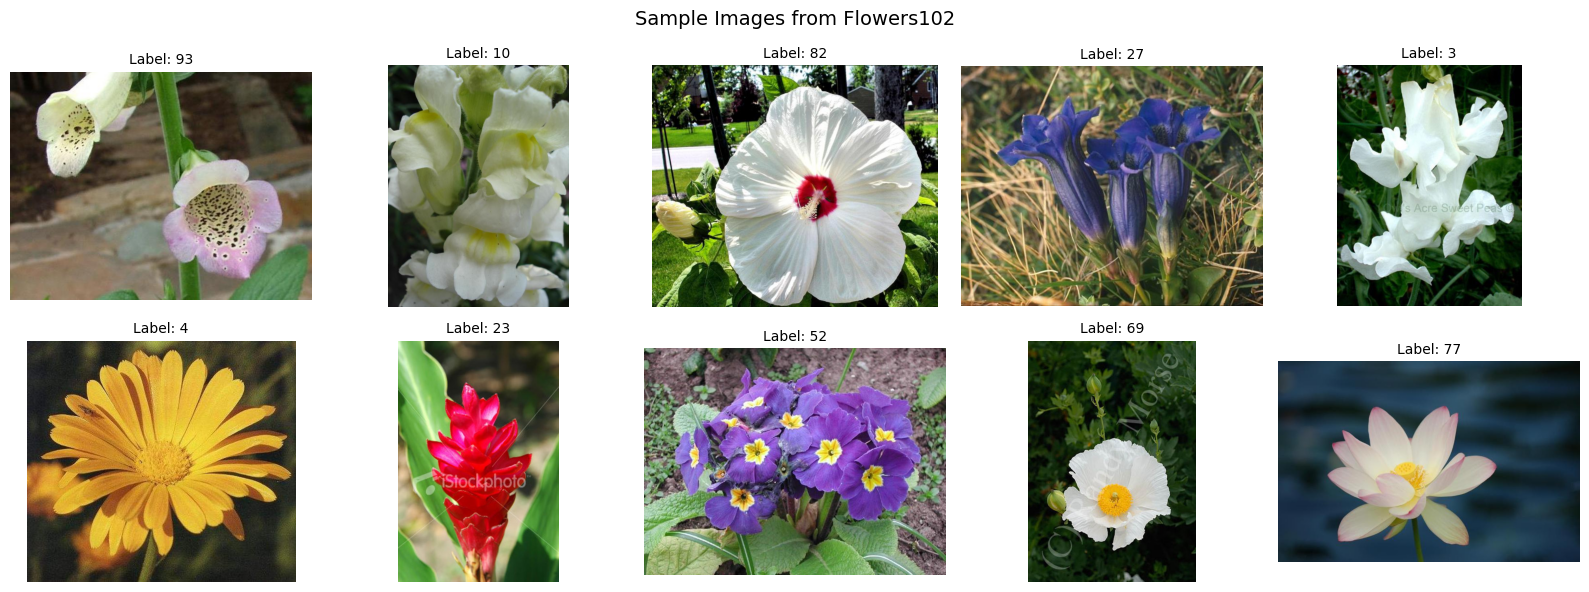

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os
os.makedirs('results', exist_ok=True)

random.Random(SEED)
# Load raw images (no transforms)
raw_ds = FlowerDataset(Path_train, y_train, transform=None)

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
fig.suptitle("Sample Images from Flowers102", fontsize=14)

for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(raw_ds) - 1)
    img, label = raw_ds[idx]
    ax.imshow(img)
    ax.set_title(f"Label: {label}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

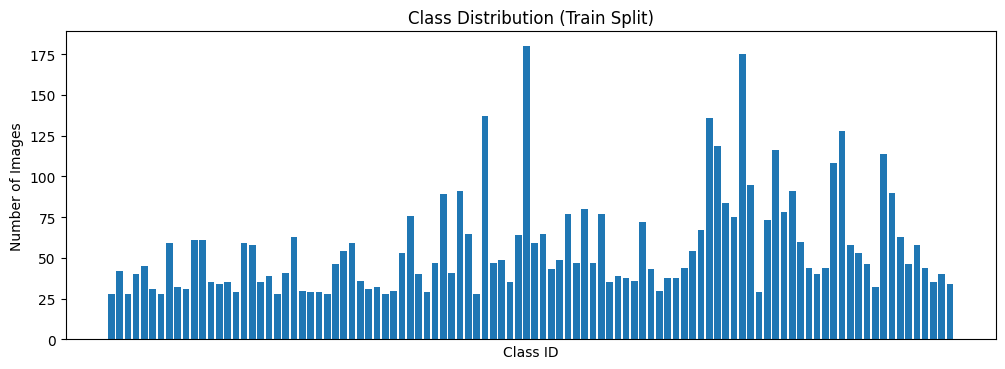

Min: 28, Max: 180, Mean: 56.2


In [ ]:
import numpy as np
os.makedirs('results', exist_ok=True)
counts = np.bincount(y_train, minlength=102)
plt.figure(figsize=(12, 4))
plt.bar(range(102), counts)
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.title("Class Distribution (Train Split)")
plt.xticks([], [])  # too many to label
plt.savefig('results/class_distribution.png', dpi=150)
plt.show()

print(f"Min: {counts.min()}, Max: {counts.max()}, Mean: {counts.mean():.1f}")

### Model A Definition (ScratchModel)

In [ ]:
class ScratchModel(nn.Module):
    def __init__(self, num_classes=102):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 512, 3, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
        )

        # 224 / 2^4 = 14
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # Global average pooling
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
model = ScratchModel()
x = torch.randn(2, 3, 224, 224)
out = model(x)
print(out.shape)  # should be [2, 102]
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

torch.Size([2, 102])
Parameters: 1,622,886


### Model B definition (ResNet)

In [ ]:
import torchvision.models as models

# Load pre-trained ResNet18
model_b = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze all backbone layers (everything except the final fc)
for param in model_b.parameters():
    param.requires_grad = False

# Replace the final fully-connected layer (was 1000 ImageNet classes → 102 flowers)
model_b.fc = nn.Linear(512, 102)

# The new fc layer is trainable by default (requires_grad=True)
print(f"Trainable params: {sum(p.numel() for p in model_b.parameters() if p.requires_grad):,}")
print(f"Total params:     {sum(p.numel() for p in model_b.parameters()):,}")

Trainable params: 52,326
Total params:     11,228,838


### Training function

In [ ]:
import time
import torch.nn as nn

def train_model(model, train_loader, val_loader, epochs=20, lr=1e-3, device='cuda'):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(1, epochs + 1):
        # --- Train ---
        model.train()
        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        scheduler.step()

        train_loss = running_loss / total
        train_acc = correct / total

        # --- Validate ---
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss /= val_total
        val_acc = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch:2d}/{epochs} | "
              f"Train Loss: {train_loss:.4f} (Acc: {train_acc:.4f}) | "
              f"Val Loss: {val_loss:.4f} (Acc: {val_acc:.4f})")

    return history

### Training the model

In [41]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

# Model A — from scratch
model_a = ScratchModel(num_classes=102)
start = time.perf_counter()
history_a = train_model(model_a, train_loader, val_loader, epochs=80, lr=1e-3, device=device)
end = time.perf_counter()
print(f"Elapsed: {end - start} seconds")
duration_a = int((end-start)/60)

Device: cuda
Epoch  1/80 | Train Loss: 3.7955 (Acc: 0.1190) | Val Loss: 3.2614 (Acc: 0.1912)
Epoch  2/80 | Train Loss: 3.2943 (Acc: 0.1940) | Val Loss: 3.0207 (Acc: 0.2449)
Epoch  3/80 | Train Loss: 3.0797 (Acc: 0.2298) | Val Loss: 2.7750 (Acc: 0.3059)
Epoch  4/80 | Train Loss: 2.9406 (Acc: 0.2582) | Val Loss: 2.6679 (Acc: 0.3198)
Epoch  5/80 | Train Loss: 2.8546 (Acc: 0.2766) | Val Loss: 2.5437 (Acc: 0.3605)
Epoch  6/80 | Train Loss: 2.7704 (Acc: 0.2924) | Val Loss: 2.5069 (Acc: 0.3450)
Epoch  7/80 | Train Loss: 2.7121 (Acc: 0.3038) | Val Loss: 2.3673 (Acc: 0.3946)
Epoch  8/80 | Train Loss: 2.6484 (Acc: 0.3239) | Val Loss: 2.4368 (Acc: 0.3792)
Epoch  9/80 | Train Loss: 2.5756 (Acc: 0.3396) | Val Loss: 2.2064 (Acc: 0.4304)
Epoch 10/80 | Train Loss: 2.4970 (Acc: 0.3511) | Val Loss: 2.2945 (Acc: 0.4036)
Epoch 11/80 | Train Loss: 2.4410 (Acc: 0.3699) | Val Loss: 2.1577 (Acc: 0.4304)
Epoch 12/80 | Train Loss: 2.4003 (Acc: 0.3778) | Val Loss: 2.0440 (Acc: 0.4540)
Epoch 13/80 | Train Loss: 2

In [42]:
# Model B — ResNet18 (only fc trainable)
start = time.perf_counter()
history_b = train_model(model_b, train_loader, val_loader, epochs=40, lr=1e-3, device=device)
end = time.perf_counter()
print(f"Elapsed: {end - start} seconds")
duration_b = int((end-start)/60)

Epoch  1/40 | Train Loss: 3.4370 (Acc: 0.3027) | Val Loss: 2.0474 (Acc: 0.6688)
Epoch  2/40 | Train Loss: 1.8434 (Acc: 0.6821) | Val Loss: 1.1623 (Acc: 0.7966)
Epoch  3/40 | Train Loss: 1.2509 (Acc: 0.7861) | Val Loss: 0.7987 (Acc: 0.8552)
Epoch  4/40 | Train Loss: 0.9861 (Acc: 0.8187) | Val Loss: 0.6470 (Acc: 0.8836)
Epoch  5/40 | Train Loss: 0.8224 (Acc: 0.8463) | Val Loss: 0.5412 (Acc: 0.8999)
Epoch  6/40 | Train Loss: 0.7139 (Acc: 0.8665) | Val Loss: 0.4793 (Acc: 0.9105)
Epoch  7/40 | Train Loss: 0.6625 (Acc: 0.8608) | Val Loss: 0.4252 (Acc: 0.9170)
Epoch  8/40 | Train Loss: 0.6251 (Acc: 0.8704) | Val Loss: 0.3905 (Acc: 0.9227)
Epoch  9/40 | Train Loss: 0.5577 (Acc: 0.8815) | Val Loss: 0.3847 (Acc: 0.9178)
Epoch 10/40 | Train Loss: 0.5276 (Acc: 0.8852) | Val Loss: 0.3513 (Acc: 0.9260)
Epoch 11/40 | Train Loss: 0.4942 (Acc: 0.8932) | Val Loss: 0.3323 (Acc: 0.9292)
Epoch 12/40 | Train Loss: 0.4888 (Acc: 0.8941) | Val Loss: 0.3180 (Acc: 0.9341)
Epoch 13/40 | Train Loss: 0.4813 (Acc: 0

In [ ]:
# Cell: Save best model
torch.save(model_b.state_dict(), 'best_model_b.pth')
torch.save(model_a.state_dict(), 'best_model_a.pth')
print("Models saved.")

### Plots

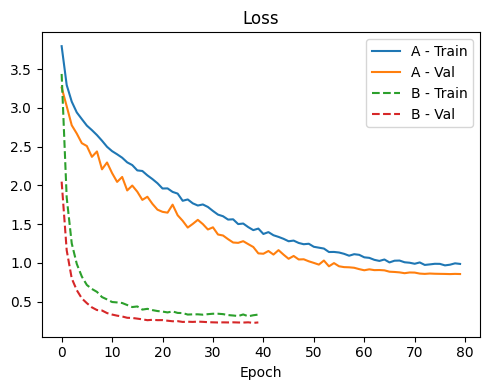

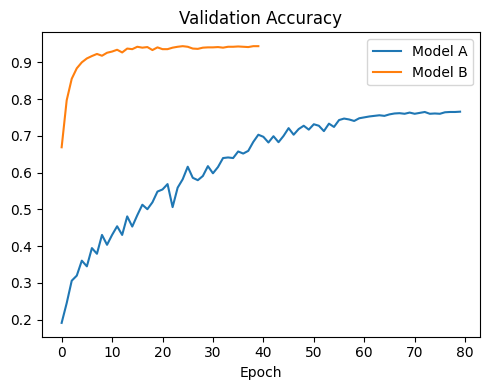

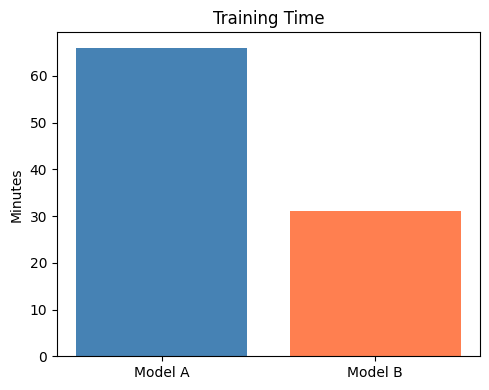

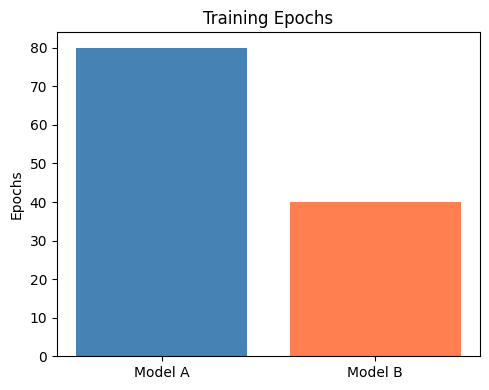

In [44]:
# curves for both models
import os
import matplotlib.pyplot as plt

os.makedirs('results', exist_ok=True)

# Chart 1: Loss curves
fig1, ax1 = plt.subplots(figsize=(5, 4))
ax1.plot(history_a['train_loss'], label='A - Train')
ax1.plot(history_a['val_loss'], label='A - Val')
ax1.plot(history_b['train_loss'], label='B - Train', linestyle='--')
ax1.plot(history_b['val_loss'], label='B - Val', linestyle='--')
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()
plt.tight_layout()
plt.savefig('results/loss.png', dpi=150)
plt.show()

# Chart 2: Validation accuracy
fig2, ax2 = plt.subplots(figsize=(5, 4))
ax2.plot(history_a['val_acc'], label='Model A')
ax2.plot(history_b['val_acc'], label='Model B')
ax2.set_title("Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()
plt.tight_layout()
plt.savefig('results/val_acc.png', dpi=150)
plt.show()

# Chart 3: Training time
fig3, ax3 = plt.subplots(figsize=(5, 4))
ax3.bar(['Model A', 'Model B'], [duration_a, duration_b], color=['steelblue', 'coral'])
ax3.set_title("Training Time")
ax3.set_ylabel("Minutes")
plt.tight_layout()
plt.savefig('results/training_time.png', dpi=150)
plt.show()

# Chart 3: Training time
fig3, ax3 = plt.subplots(figsize=(5, 4))
ax3.bar(['Model A', 'Model B'], [80, 40], color=['steelblue', 'coral'])
ax3.set_title("Training Epochs")
ax3.set_ylabel("Epochs")
plt.tight_layout()
plt.savefig('results/training_epoch.png', dpi=150)
plt.show()

Test Accuracy: 0.7673
Test Accuracy: 0.9365


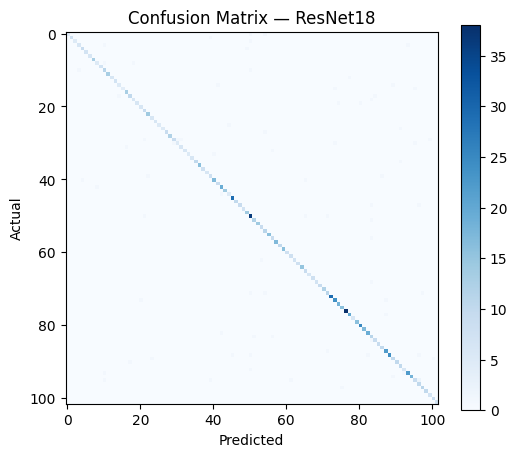

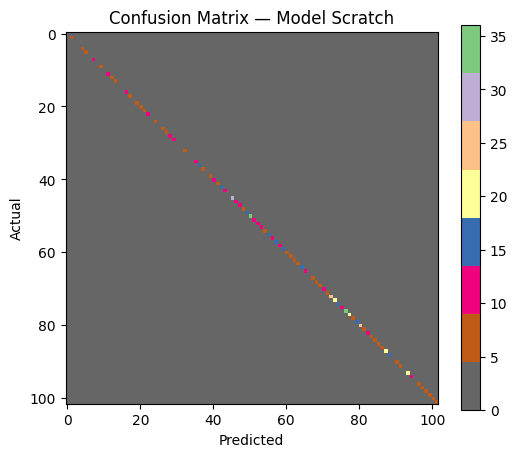

In [46]:
import os
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

os.makedirs('results', exist_ok=True)

def evaluate(model, test_loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    acc = np.mean(np.array(all_preds) == np.array(all_labels))
    print(f"Test Accuracy: {acc:.4f}")
    return np.array(all_preds), np.array(all_labels)

preds_a, labels_test = evaluate(model_a, test_loader, device)
preds_b, _           = evaluate(model_b, test_loader, device)

# Confusion matrix (ResNet18)
cm = confusion_matrix(labels_test, preds_b)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix — ResNet18")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig('results/confusion_matrix_b.png', dpi=150)
plt.show()

# Confusion matrix
cm_2 = confusion_matrix(labels_test, preds_a)
plt.figure(figsize=(6, 5))
plt.imshow(cm_2, cmap='Accent_r')
plt.title("Confusion Matrix — Model Scratch")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig('results/confusion_matrix_a.png', dpi=150)
plt.show()

In [59]:
# Pick 20 test images, get predictions + confidence
import pandas as pd
model_b.eval()
samples = []
with torch.no_grad():
    for i, (images, labels) in enumerate(test_loader):
        if i >= 1:  # just first batch
            break
        images = images.to(device)
        outputs = model_b(images)
        probs = torch.softmax(outputs, dim=1)
        conf, preds = probs.max(1)

        for j in range(20):
            samples.append({
                'path': Path_test[j].name,
                #'image': images[j].cpu(),
                'pred': preds[j].item(),
                'true': labels[j].item(),
                'confidence': conf[j].item()

            })

dataframe = pd.DataFrame(samples)

In [62]:
dataframe

,path,pred,true,confidence
0,image_07745.jpg,96,96,0.660346
1,image_00150.jpg,76,76,0.998205
2,image_01849.jpg,77,77,0.997653
3,image_06430.jpg,8,8,0.773792
4,image_01102.jpg,45,45,0.997805
5,image_01764.jpg,82,82,0.769985
6,image_05880.jpg,62,62,0.997262
7,image_08085.jpg,34,34,0.999325
8,image_02106.jpg,74,74,0.993659
9,image_03553.jpg,71,71,0.431348


In [60]:
dataframe.to_csv('sample_predictions.csv', index=False)

In [61]:
files.download('sample_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
# Save & download all artifacts (models + charts)
import os, zipfile
os.makedirs('results', exist_ok=True)

# Make sure models exist (re-save in case the earlier cell was skipped)
torch.save(model_b.state_dict(), 'best_model_b.pth')
torch.save(model_a.state_dict(), 'best_model_a.pth')

# Bundle everything into one zip for easy download
with zipfile.ZipFile('flower_results.zip', 'w') as z:
    for f in ['best_model_b.pth', 'best_model_a.pth',
              'results/confusion_matrix_b.png', 'results/confusion_matrix_a.png',
              'results/loss.png', 'results/training_time.png',
              'results/val_acc.png', 'results/training_epoch.png',
              'sample_predictions.csv']:
        if os.path.exists(f):
            z.write(f)

from google.colab import files
files.download('best_model_b.pth')
files.download('best_model_a.pth')
files.download('flower_results.zip')
print("Downloaded: best_model_b.pth, best_model_a.pth, flower_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: best_model_b.pth, best_model_a.pth, flower_results.zip


In [49]:
files.download('results/class_distribution.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>